 ## DEM of Difference (DoD) & Volume of Erosion/Deposition with Stable-Area Bias Correction

## Workflow:

### 1. Compute initial DoD = after - before (on a user-selectable grid).
### 2. Load a **stable-areas shapefile** (roads, bedrock, buildings...).
### 3. Run **zonal statistics** of DoD within those polygons.
### 4. Subtract the mean stable-area DoD (systematic offset) from the "after" DEM.
### 5. Recompute the DoD -> stable areas now center on ~0 (+/- ~0.02 m).
### 6. Compute erosion/deposition volumes from the corrected DoD.
### - Erosion volume (negative change) and Deposition volume (positive change)

### A **Level of Detection (LoD)** threshold masks out changes below survey noise.
### The **output grid/extent is user-selectable** via CLIP_TO. 

#### CRS: EPSG:25832.


In [ ]:
# USER CONFIGURATION

DEM_BEFORE_PATH = "data/dem_2025.tif"   # earlier survey
DEM_AFTER_PATH  = "data/dem_2026.tif"   # later survey
OUTPUT_DOD_PATH = "output/dod.tif"
STABLE_SHP_PATH   = "data/stable_areas.shp"   # polygons over stable ground

# Reference grid selection

# Which DEM's grid (resolution, extent, alignment) should the RESULT match?
#   "before" -> clip/align to DEM_BEFORE_PATH
#   "after"  -> clip/align to DEM_AFTER_PATH
#   "custom" -> clip/align to CUSTOM_REF_PATH below

CLIP_TO          = "after"
CUSTOM_REF_PATH  = "data/aoi_reference.tif"   # only used if CLIP_TO == "custom"

# Resampling method for aligning the non-reference DEM(s) to the chosen grid.
RESAMPLING       = "bilinear"   # "bilinear", "nearest", or "cubic"

# Level of Detection: ignore change below this value (metres).
# Set from your DEM vertical uncertainty; use 0.0 to disable.
LOD_THRESHOLD   = 0.15

# Acceptance tolerance for the corrected stable area (metres).
STABLE_TOLERANCE  = 0.02

In [ ]:
# Import required Libraries

import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize
from dem_utils import read_dem, write_raster


# Map string -> rasterio Resampling enum
_RESAMPLING_MAP = {
    "nearest":  Resampling.nearest,
    "bilinear": Resampling.bilinear,
    "cubic":    Resampling.cubic,
}
resampling_method = _RESAMPLING_MAP.get(RESAMPLING, Resampling.bilinear)

In [57]:
# The chosen DEM defines the output resolution, extent and alignment.
# Both epoch DEMs are then resampled onto this reference grid.

def resolve_reference_path(clip_to, before, after, custom):
    """Return the path of the raster that defines the output grid."""
    if clip_to == "before":
        return before
    elif clip_to == "after":
        return after
    elif clip_to == "custom":
        return custom
    raise ValueError("CLIP_TO must be 'before', 'after', or 'custom'.")

REF_PATH = resolve_reference_path(
    CLIP_TO, DEM_BEFORE_PATH, DEM_AFTER_PATH, CUSTOM_REF_PATH
)
print(f"Output will be clipped/aligned to: {REF_PATH}  (CLIP_TO='{CLIP_TO}')")

# Read reference grid definition (we only need its geometry/profile)
with rasterio.open(REF_PATH) as ref:
    ref_profile   = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs       = ref.crs
    ref_shape     = (ref.height, ref.width)
    res_x, res_y  = ref.res

    if ref_crs is None:
        print("WARNING: Reference has no CRS. Assuming EPSG:25832.")
    elif ref_crs.to_epsg() != 25832:
        print(f"WARNING: Reference CRS is {ref_crs}. Expected EPSG:25832.")

pixel_area = abs(res_x * res_y)   # m^2 per cell
print(f"Reference grid: {ref_shape} cells, "
      f"pixel size {res_x} x {res_y} m -> cell area {pixel_area:.4f} m^2")

Output will be clipped/aligned to: data/dem_2026.tif  (CLIP_TO='after')
Reference grid: (1546, 1322) cells, pixel size 0.25 x 0.25 m -> cell area 0.0625 m^2


In [58]:
# load any DEM onto the reference grid

def load_on_reference(path, ref_transform, ref_crs, ref_shape, resampling):
    """Read a DEM and resample/reproject it onto the reference grid.
    Returns a float64 array (NoData -> NaN)."""
    destination = np.full(ref_shape, np.nan, dtype="float64")
    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=resampling,
            src_nodata=src.nodata,
            dst_nodata=np.nan,
        )
    return destination


In [ ]:
# Load both epochs onto the chosen reference grid
# The DEM that is the reference is still read through the same path,
# so the workflow is identical regardless of CLIP_TO.

before = load_on_reference(
    DEM_BEFORE_PATH, ref_transform, ref_crs, ref_shape, resampling_method
)
after = load_on_reference(
    DEM_AFTER_PATH, ref_transform, ref_crs, ref_shape, resampling_method
)

# Optionally use the custom reference as an AOI mask (only where it has data)
if CLIP_TO == "custom":
    ref_mask = load_on_reference(
        CUSTOM_REF_PATH, ref_transform, ref_crs, ref_shape, Resampling.nearest
    )
    aoi = ~np.isnan(ref_mask)
    before = np.where(aoi, before, np.nan)
    after  = np.where(aoi, after,  np.nan)
    print(f"AOI mask applied from custom reference: "
          f"{np.sum(aoi):,} valid cells.")


# Rasterize the stable-areas shapefile onto the reference grid
stable_gdf = gpd.read_file(STABLE_SHP_PATH)
print(f"Loaded {len(stable_gdf)} stable-area polygon(s).")

# Ensure CRS matches the reference grid
if stable_gdf.crs is None:
    print("WARNING: shapefile has no CRS. Assuming EPSG:25832.")
    stable_gdf = stable_gdf.set_crs(epsg=25832)
elif stable_gdf.crs.to_epsg() != ref_crs.to_epsg():
    print(f"Reprojecting shapefile {stable_gdf.crs} -> {ref_crs}")
    stable_gdf = stable_gdf.to_crs(ref_crs)

stable_mask = rasterize(
    [(geom, 1) for geom in stable_gdf.geometry],
    out_shape=ref_shape,
    transform=ref_transform,
    fill=0,
    dtype="uint8",
).astype(bool)

print(f"Stable-area pixels: {stable_mask.sum():,}")

In [60]:
# Load and align DEMs

# The 'after' DEM is resampled onto the 'before' DEM grid so the pixels match.

with rasterio.open(DEM_BEFORE_PATH) as ref:
    before = ref.read(1).astype("float64")
    ref_profile = ref.profile.copy()
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_nodata = ref.nodata
    res_x, res_y = ref.res

if ref_nodata is not None:
    before[before == ref_nodata] = np.nan

# Reproject/resample 'after' to the reference grid
after = np.empty_like(before)
with rasterio.open(DEM_AFTER_PATH) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=after,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=ref_transform,
        dst_crs=ref_crs,
        resampling=Resampling.bilinear,
        dst_nodata=np.nan,
    )

pixel_area = abs(res_x * res_y)   # m^2 per cell
print(f"Pixel size: {res_x} x {res_y} m  ->  cell area = {pixel_area:.4f} m^2")

Pixel size: 0.25 x 0.25 m  ->  cell area = 0.0625 m^2


In [ ]:
# Compute Initial DEM of Difference (DoD)
dod = after - before   # positive = gain (deposition), negative = loss (erosion)


# Validate stable DoD values
stable_vals = dod_initial[stable_mask & ~np.isnan(dod_initial)]
if stable_vals.size == 0:
    raise ValueError("No valid DoD values found within stable polygons. "
                     "Check shapefile placement / DEM overlap.")


# Zonal statistics of the DoD over stable areas
stable_mean   = np.mean(stable_vals)
stable_median = np.median(stable_vals)
stable_std    = np.std(stable_vals)

print("=== STABLE-AREA ZONAL STATISTICS (before correction) ===")
print(f"Count  : {stable_vals.size:,} cells")
print(f"Mean   : {stable_mean:+.4f} m   <-- systematic vertical offset")
print(f"Median : {stable_median:+.4f} m")
print(f"Std    : {stable_std:.4f} m")
print(f"Min/Max: {stable_vals.min():+.4f} / {stable_vals.max():+.4f} m")

In [ ]:
# Correct the "after" DEM by subtracting the offset
# Subtracting the stable-area mean removes the systematic bias so that
# stable ground differences center on zero.

after_corrected = after - stable_mean
print(f"Applied vertical correction to 'after' DEM: {-stable_mean:+.4f} m")

# Recompute the corrected DoD
dod = after_corrected - before   # corrected DoD

# Verify the correction over stable areas
stable_vals_corr = dod[stable_mask & ~np.isnan(dod)]
corr_mean = np.mean(stable_vals_corr)
within_tol = np.mean(np.abs(stable_vals_corr) <= STABLE_TOLERANCE) * 100.0

print("=== STABLE-AREA CHECK (corrected DoD) ===")
print(f"Mean residual : {corr_mean:+.4f} m  (target ~0)")
print(f"Std residual  : {np.std(stable_vals_corr):.4f} m")
print(f"Cells within +/-{STABLE_TOLERANCE} m : {within_tol:.1f}%")
if abs(corr_mean) <= STABLE_TOLERANCE:
    print("PASS: stable-area mean is within tolerance.")
else:
    print("NOTE: residual mean exceeds tolerance — check for tilt/non-uniform bias.")


In [ ]:
# Apply Level of Detection to the corrected DoD
if LOD_THRESHOLD > 0:
    dod_thresh = np.where(np.abs(dod) < LOD_THRESHOLD, np.nan, dod)
else:
    dod_thresh = dod.copy()

In [ ]:
# Calculate Volume of deposition and erosion of corrected DOD

valid = ~np.isnan(dod_thresh)

deposition = np.where(dod_thresh > 0, dod_thresh, 0.0)
erosion    = np.where(dod_thresh < 0, dod_thresh, 0.0)

vol_deposition = np.nansum(deposition) * pixel_area          # m^3 (+)
vol_erosion    = np.nansum(erosion) * pixel_area             # m^3 (-)
net_volume     = vol_deposition + vol_erosion                # m^3

area_deposition = np.sum(dod_thresh > 0) * pixel_area        # m^2
area_erosion    = np.sum(dod_thresh < 0) * pixel_area        # m^2

print("=== FINAL VOLUME CHANGE REPORT (bias-corrected) ===")
print(f"Vertical correction applied : {-stable_mean:+.4f} m")
print(f"Level of Detection: {LOD_THRESHOLD} m")
print(f"Deposition volume : {vol_deposition:,.2f} m^3  over {area_deposition:,.1f} m^2")
print(f"Erosion volume    : {vol_erosion:,.2f} m^3  over {area_erosion:,.1f} m^2")
print(f"Net volume change : {net_volume:,.2f} m^3")

=== VOLUME CHANGE REPORT ===
Clipped to grid   : after (data/dem_2026.tif)
Level of Detection: 0.15 m
Deposition volume : 13.54 m^3  over 31.0 m^2
Erosion volume    : -69,710.62 m^3  over 49,656.6 m^2
Net volume change : -69,697.07 m^3


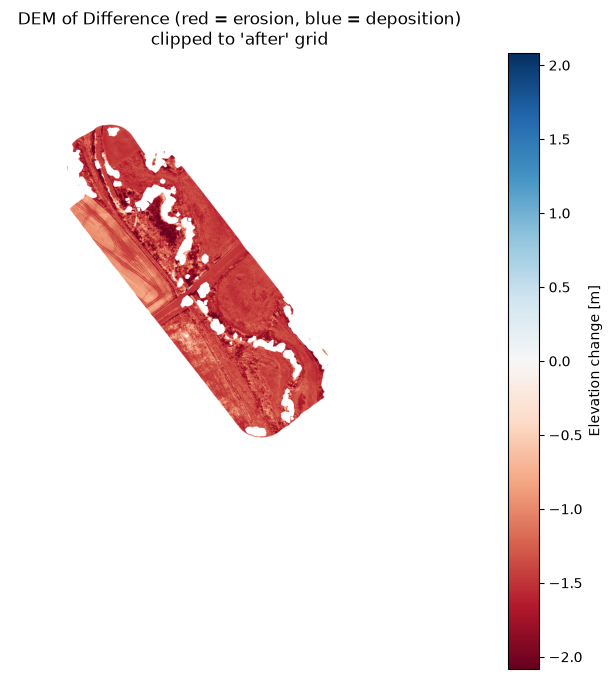

In [ ]:
# Visualize the DoD and save to output file

vmax = np.nanpercentile(np.abs(dod_thresh), 98)

# Copy the colormap to set NaN (below-LoD / stable) cells to white
cmap = plt.colormaps["RdBu"].copy()
cmap.set_bad(color="white")      # NaN (stable areas) -> white

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(dod_thresh, cmap=cmap, vmin=-vmax, vmax=vmax)
plt.colorbar(im, label="Elevation change [m]")

# Outline stable polygons for reference
stable_gdf.boundary.plot(ax=ax, edgecolor="black", linewidth=0.6, transform=ax.transData)

ax.set_title("Bias-Corrected DEM of Difference\n"
          "(red=erosion, blue=deposition, white=stable/no change)")
ax.axis("off")
plt.show()

In [ ]:
# Save DoD raster

write_raster(OUTPUT_DOD_PATH, dod_thresh, ref_profile)